# NumCompute streaming weather demo

Predict **RainTomorrow** from observations available on the current day. Three otherwise identical pipelines process the same Adelaide weather CSV in date order. They predict each chunk before learning its labels and retrain after 30, 60 or 120 pending rows.

The bundled Adelaide 2015 extract is described in the [dataset credits](../README.md#demo-data-and-credit). This replay treats labels as available after each chunk. A live forecast would need to account for the actual label delay.

In [1]:
%matplotlib inline
from pathlib import Path

from IPython.display import Markdown, display
from matplotlib import pyplot as plt
import numpy as np

from numcompute.io import load_csv_chunks, read_header
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import Imputer, StandardScaler
from numcompute_stream.stats import StreamingStats
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.visualise import (
    compare_models,
    plot_metric_over_time,
    plot_predictions_vs_ground_truth,
)

source = Path("data/adelaide_weather_2015.csv")
path = next((root / source for root in (Path.cwd(), Path.cwd().parent)
             if (root / source).is_file()), None)
if path is None:
    raise FileNotFoundError("Open this notebook from the repository root or demo directory.")

chunk_size = 10
buffer_sizes = (30, 60, 120)
rolling_rows = 40
features = ("MinTemp", "MaxTemp", "Rainfall", "WindGustSpeed",
            "Humidity3pm", "Pressure3pm", "Temp3pm")
header = read_header(path)
print(f"Reading {path.name} in chunks of up to {chunk_size} rows")
print("Features:", ", ".join(features))

Matplotlib is building the font cache; this may take a moment.


Reading adelaide_weather_2015.csv in chunks of up to 10 rows
Features: MinTemp, MaxTemp, Rainfall, WindGustSpeed, Humidity3pm, Pressure3pm, Temp3pm


## Replay the CSV

The custom CSV reader keeps numeric features and date/label fields in aligned blocks. Missing numeric values remain NaN until the pipeline imputes them. Dates track order and never enter the classifier. The pipeline buffers raw rows and deploys each new tree with the imputer and scaler used to train it.

In [2]:
def make_trainer(buffer_size):
    pipe = Pipeline([
        ("impute", Imputer()),
        ("scale", StandardScaler()),
        ("tree", DecisionTreeClassifier(max_depth=5, buffer_size=buffer_size,
                                        criterion="gini", random_state=42)),
    ])
    return StreamTrainer(pipe, pos_label="Yes", window_size=rolling_rows)


def weather_chunks():
    options = dict(chunk_size=chunk_size, skip_header=1)
    numeric = load_csv_chunks(path, usecols=[header.index(name) for name in features], **options)
    text = load_csv_chunks(path, usecols=[header.index("Date"), header.index("RainTomorrow")],
                           dtype=str, **options)
    previous_date = None
    for X, block in zip(numeric, text, strict=True):
        assert len(X) == len(block)
        dates, labels = block.T
        assert np.all(dates[1:] > dates[:-1])
        assert previous_date is None or dates[0] > previous_date
        previous_date = dates[-1]
        known = np.isin(labels, ["No", "Yes"])
        if known.any():
            yield dates[known], X[known], labels[known]


trainers = {size: make_trainer(size) for size in buffer_sizes}
recent_rain = StreamingStats(window_size=30, bins=[0, 0.1, 1, 5, 20, 100])
example_size = buffer_sizes[0]
last_dates = None
for dates, X, y in weather_chunks():
    recent_rain.update_stats(X[:, [features.index("Rainfall")]])
    for size, trainer in trainers.items():
        trainer.fit_chunk(X, y)
        if size == example_size and trainer.latest_score is not None:
            last_dates = dates

focus = trainers[example_size]
print(f"Processed {focus.logs[-1].rows_seen} labelled rows in {len(focus.logs)} chunks.")
print(f"Median rainfall over the latest 30 rows: {recent_rain.quantile(0.5).item():.1f} mm")

Processed 360 labelled rows in 36 chunks.
Median rainfall over the latest 30 rows: 0.0 mm


## Inspect warm-up and retraining

A **yes** in the Fit column means the incoming chunk reached the buffer threshold and triggered a fresh fit. The first such chunk still has no prediction because it was evaluated before training. The memory estimate covers retained model and buffer arrays after the update. Update time includes preprocessing, buffering and training on triggering chunks.

In [3]:
def show_table(headers, rows):
    def line(values):
        return "| " + " | ".join(map(str, values)) + " |"
    display(Markdown("\n".join([line(headers), line(["---"] * len(headers)),
                                *[line(row) for row in rows]])))


def percentage(value):
    return f"{value:.1%}" if np.isfinite(value) else "—"


show_table(
    ["Chunk", "Rows seen", "Pending", "Fit", "Chunk accuracy", "Cumulative",
     "Rolling", "Retrain update (ms)", "Retained (KiB)"],
    [(log.chunk, log.rows_seen, log.pending_rows, "yes" if log.retrained else "",
      percentage(log.chunk_accuracy), percentage(log.cumulative_accuracy),
      percentage(log.rolling_accuracy), f"{log.retrain_seconds * 1000:.2f}",
      f"{log.model_array_bytes / 1024:.1f}") for log in focus.logs[:9]],
)
print(f"Buffer {example_size}. Final cumulative AUC: {focus.result()['auc']:.3f}")

| Chunk | Rows seen | Pending | Fit | Chunk accuracy | Cumulative | Rolling | Retrain update (ms) | Retained (KiB) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 10 | 10 |  | — | — | — | 0.00 | 1.3 |
| 2 | 20 | 20 |  | — | — | — | 0.00 | 2.2 |
| 3 | 30 | 0 | yes | — | — | — | 89.04 | 0.5 |
| 4 | 40 | 10 |  | 100.0% | 100.0% | 100.0% | 0.00 | 1.7 |
| 5 | 50 | 20 |  | 80.0% | 90.0% | 90.0% | 0.00 | 2.7 |
| 6 | 60 | 0 | yes | 90.0% | 90.0% | 90.0% | 0.42 | 0.4 |
| 7 | 70 | 10 |  | 100.0% | 92.5% | 92.5% | 0.00 | 1.6 |
| 8 | 80 | 20 |  | 100.0% | 94.0% | 92.5% | 0.00 | 2.6 |
| 9 | 90 | 0 | yes | 100.0% | 95.0% | 97.5% | 0.29 | 0.4 |

Buffer 30. Final cumulative AUC: 0.628


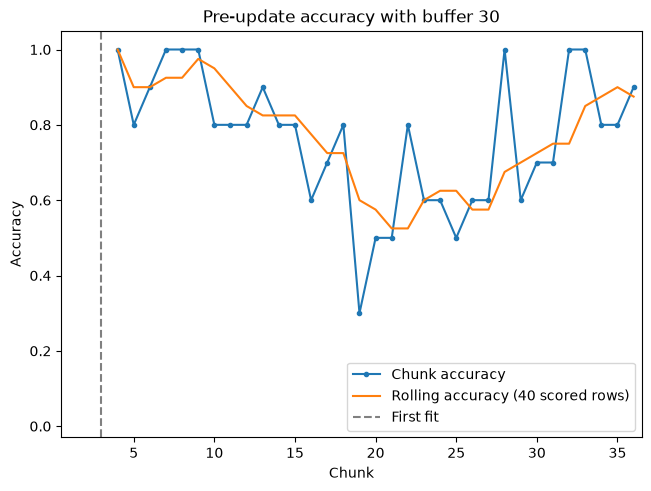

In [4]:
ax = plot_metric_over_time([entry.chunk_accuracy for entry in focus.logs],
                           f"Pre-update accuracy with buffer {example_size}", "Accuracy")
ax.lines[0].set_label("Chunk accuracy")
ax.plot([log.chunk for log in focus.logs], [log.rolling_accuracy for log in focus.logs],
        label=f"Rolling accuracy ({rolling_rows} scored rows)")
first_fit = next(log.chunk for log in focus.logs if log.retrained)
ax.axvline(first_fit, color="0.5", linestyle="--", label="First fit")
ax.set_ylim(-0.03, 1.05)
ax.legend(loc="lower right")
plt.show()

## Compare buffer sizes on common rows

A larger buffer usually needs more warm-up rows before it can predict. Coverage reports how many rows each model scored. For a fair accuracy comparison, start at the first chunk scored by **every** buffer size and weight chunk accuracies by the number of rows in each chunk.

In [5]:
first_common = max(next(log.chunk for log in trainer.logs if np.isfinite(log.chunk_accuracy))
                   for trainer in trainers.values())
comparison = []
for size, trainer in trainers.items():
    common = trainer.logs[first_common - 1:]
    assert all(np.isfinite(log.chunk_accuracy) for log in common)
    n_common = sum(log.rows for log in common)
    shared_accuracy = sum(log.rows * log.chunk_accuracy for log in common) / n_common
    last = trainer.logs[-1]
    comparison.append((size, f"{last.scored_samples}/{last.rows_seen}",
                       percentage(last.scored_samples / last.rows_seen), n_common,
                       percentage(shared_accuracy), sum(log.retrained for log in trainer.logs)))
show_table(["Buffer", "Rows scored", "Coverage", "Common rows", "Common accuracy", "Fits"],
           comparison)
print(f"Common comparison starts at chunk {first_common}.")

| Buffer | Rows scored | Coverage | Common rows | Common accuracy | Fits |
| --- | --- | --- | --- | --- | --- |
| 30 | 330/360 | 91.7% | 240 | 71.2% | 12 |
| 60 | 300/360 | 83.3% | 240 | 69.6% | 6 |
| 120 | 240/360 | 66.7% | 240 | 65.8% | 3 |

Common comparison starts at chunk 13.


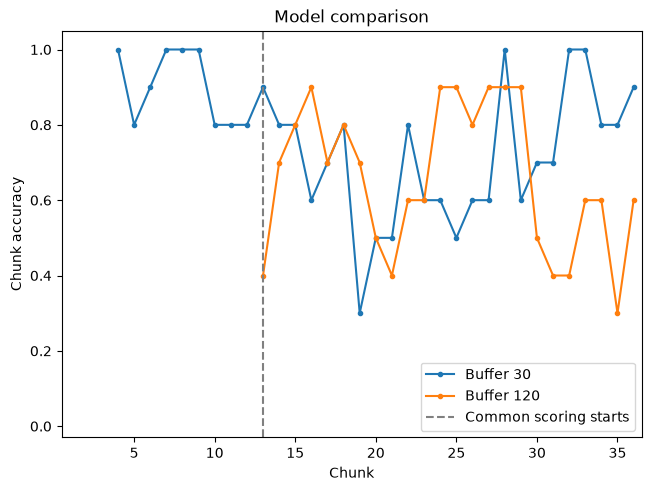

In [6]:
largest = buffer_sizes[-1]
ax = compare_models([log.chunk_accuracy for log in focus.logs],
                    [log.chunk_accuracy for log in trainers[largest].logs],
                    (f"Buffer {example_size}", f"Buffer {largest}"))
ax.set_ylabel("Chunk accuracy")
ax.axvline(first_common, color="0.5", linestyle="--", label="Common scoring starts")
ax.set_ylim(-0.03, 1.05)
ax.legend(loc="lower right")
plt.show()

## Look at the latest predictions

Each point compares the model's pre-update prediction with the actual label for the same row. These predictions are saved when the chunk is evaluated, so a later refit cannot change them.

| Observation date | Rain tomorrow | Prediction |
| --- | --- | --- |
| 2015-12-22 | No | No |
| 2015-12-23 | No | No |
| 2015-12-24 | No | Yes |
| 2015-12-25 | Yes | Yes |
| 2015-12-26 | No | No |
| 2015-12-27 | No | No |
| 2015-12-28 | No | No |
| 2015-12-29 | No | No |
| 2015-12-30 | No | No |
| 2015-12-31 | No | No |

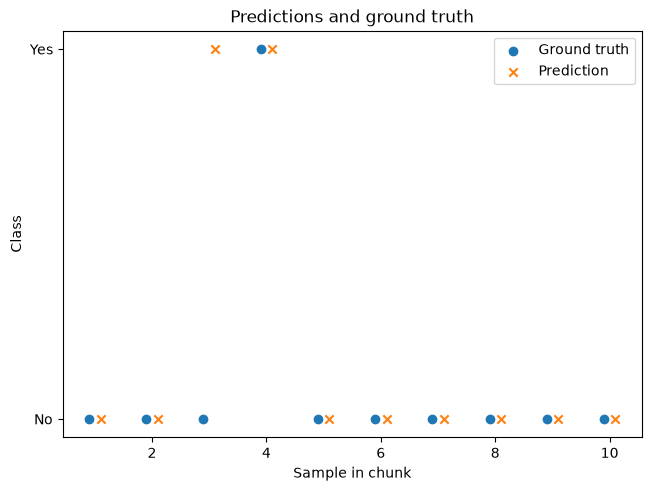

In [7]:
latest = focus.latest_score
assert len(last_dates) == len(latest.y_true)
show_table(["Observation date", "Rain tomorrow", "Prediction"],
           list(zip(last_dates, latest.y_true, latest.y_pred)))
plot_predictions_vs_ground_truth(latest.y_true, latest.y_pred)
plt.show()

## Reproduce the benchmark

The [streaming benchmark](../benchmark/stream_results.md) checks the tree's NumPy split search against a Python loop and measures how buffer size affects prediction coverage, retraining time and adaptation to a known label-rule reversal. The weather results above describe this one chronological replay.